# Численное моделирование охлаждения процессора
**Стационарная теплопроводность в кубическом теплоотводе**

Цель — найти распределение температуры в теплоотводе и оценить температуру площадки контакта с процессором.

## 1. Геометрия и физические допущения
Теплоотвод — однородный куб со стороной $L$. В центре нижней грани $z=0$ расположена квадратная площадка
со стороной $a$, через которую процессор передаёт мощность $P$.
Внутри теплоотвода тепло не выделяется.

Для охлаждения выбираются грани $-X,+X,-Y,+Y,+Z$. На них вода имеет заданную температуру $T_w$,
а теплоотдача описывается постоянным коэффициентом $\alpha$. Остальная поверхность теплоизолирована.
Рассматривается установившийся режим; движение и нагрев воды отдельно не рассчитываются.

| Параметр | Обозначение | Значение по умолчанию |
|---|---|---:|
| Сторона теплоотвода | $L$ | 0,05 м |
| Сторона площадки нагрева | $a$ | 0,03 м |
| Мощность процессора | $P$ | 200 Вт |
| Теплопроводность | $\lambda$ | 200 Вт/(м·К) |
| Температура воды | $T_w$ | 20 °C |
| Коэффициент теплоотдачи | $\alpha$ | 2000 Вт/(м²·К) |
| Число ячеек по каждой оси | $N$ | 16 |

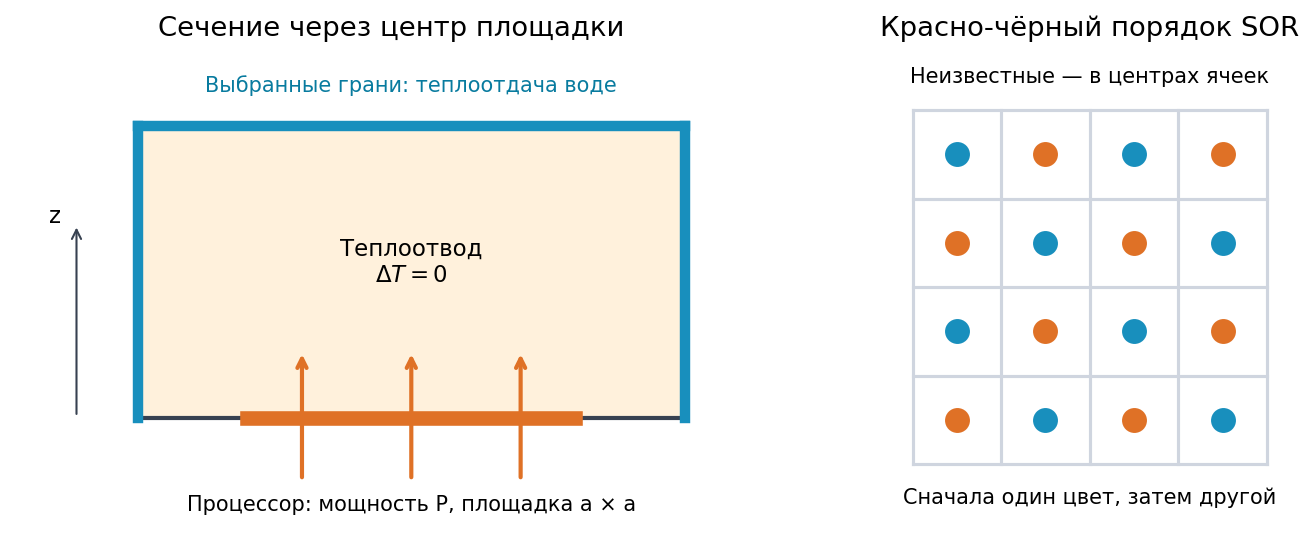

*Слева показан пример выбора охлаждаемых граней; снизу нагревается только центральная площадка. Справа — сечение раскраски трёхмерной сетки.*

## 2. Математическая постановка
Плотность теплового потока определяется законом Фурье:
$$\mathbf j=-\lambda\nabla T.$$

В установившемся режиме тепло не накапливается. Поскольку внутри материала нет источников, для любого объёма $V$ внутри теплоотвода суммарный выходящий поток равен нулю. По теореме Гаусса — Остроградского:
$$\oint_{\partial V}\mathbf j\cdot\mathbf n\,dS
=\int_V\operatorname{div}\mathbf j\,dV=0.$$
Из произвольности $V$ следует $\operatorname{div}\mathbf j=0$. При постоянной теплопроводности $\lambda$ закон Фурье даёт
$$\boxed{\Delta T=0.}$$

Граничные условия задают обмен теплом через внешнюю поверхность. Здесь $\mathbf n$ — внешняя нормаль, поэтому $\mathbf j\cdot\mathbf n$ положителен при выходе тепла из куба.

| Участок | Физическое условие | Формула |
|---|---|---|
| Площадка процессора | Мощность $P$ равномерно поступает внутрь через площадь $a^2$ | $-\lambda\,\partial T/\partial n=-P/a^2$ |
| Охлаждаемые грани | Закон теплоотдачи Ньютона | $-\lambda\,\partial T/\partial n=\alpha(T-T_w)$ |
| Остальная поверхность | Тепло не проходит через границу | $\partial T/\partial n=0$ |

Для расчёта вводим $u=T-T_w$. Поскольку температура воды постоянна, $\Delta u=0$, а на охлаждаемой поверхности $\mathbf j\cdot\mathbf n=\alpha u$.


## 3. Дискретизация: баланс тепла в ячейке
Куб делим на $N^3$ ячеек со стороной $h=L/N$. Неизвестная $u_p=u_{i,j,k}$ — превышение температуры в центре ячейки над температурой воды.

**Обмен между соседними ячейками.** По закону Фурье мощность равна теплопроводности, умноженной на площадь грани $h^2$ и на перепад температуры, делённый на расстояние между центрами $h$:
$$Q_{p\to q}\approx\lambda h^2\frac{u_p-u_q}{h}
=\lambda h(u_p-u_q).$$
Положительное значение означает выход тепла из ячейки $p$.

У внутренней ячейки шесть соседей. Из условия отсутствия накопления тепла:
$$\sum_{q\in\mathcal N(p)}Q_{p\to q}=0
\quad\Longrightarrow\quad
\boxed{6u_p-\sum_{q\in\mathcal N(p)}u_q=0.}$$
Это сеточный баланс потоков (метод конечных объёмов); для внутренней ячейки он совпадает с центральной разностной аппроксимацией $\Delta u=0$.

**Отвод тепла в воду.** От центра граничной ячейки тепло проходит через слой материала толщиной $h/2$, затем передаётся воде. Обозначим превышение температуры поверхности над температурой воды через $u_s$. По закону Фурье и закону теплоотдачи через оба участка проходит одна и та же мощность:
$$Q_f=\lambda h^2\frac{u_p-u_s}{h/2},
\qquad Q_f=\alpha h^2u_s.$$
Выражая перепады температуры и складывая их, получаем
$$u_p=(u_p-u_s)+u_s
=\frac{Q_f}{h^2}\left(\frac{h}{2\lambda}+\frac1\alpha\right).$$
Следовательно,
$$\boxed{Q_f=\frac{h^2u_p}{h/(2\lambda)+1/\alpha}
=\lambda h\beta u_p,\qquad
\beta=\frac{1}{1/2+\lambda/(\alpha h)}.}$$
Через теплоизолированную грань мощность равна нулю.

**Подвод тепла от процессора.** Плотность входящей мощности равна $P/a^2$. Если $S_{ij}$ — площадь пересечения площадки нагрева с нижней гранью ячейки, то
$$\boxed{P_{ij}=\frac{P}{a^2}S_{ij}.}$$
Так как $\sum_{ij}S_{ij}=a^2$, полная подведённая мощность сохраняется: $\sum_{ij}P_{ij}=P$.

**Общее уравнение ячейки.** Сумма мощностей, уходящих к соседям и в воду, равна подведённой мощности $P_p$:
$$\lambda h\sum_{q\in\mathcal N(p)}(u_p-u_q)
+m_p\lambda h\beta u_p=P_p,$$
где $m_p$ — число охлаждаемых внешних граней этой ячейки. После деления на $\lambda h$:
$$\boxed{d_pu_p-\sum_{q\in\mathcal N(p)}u_q=b_p,\qquad
 d_p=n_p+m_p\beta,\qquad b_p=\frac{P_p}{\lambda h}.}$$
Здесь $n_p$ — число реальных соседних ячеек; $P_p=P_{ij}$ в нижнем слое и $P_p=0$ в остальных слоях. Все уравнения вместе образуют СЛАУ $A\mathbf u=\mathbf b$.


## 4. Итерационное решение СЛАУ
Из уравнения ячейки выражаем её температуру через температуры соседей:
$$u_p=\frac{\sum_{q\in\mathcal N(p)}u_q+b_p}{d_p}.$$
Эта формула лежит в основе итерационных методов. Полную матрицу хранить не требуется: функция `neighbors(u)` вычисляет сумму температур соседей.

**Метод Якоби.** В правую часть подставляем значения предыдущей итерации:
$$u_p^{(m+1)}=\frac{\sum_{q\in\mathcal N(p)}u_q^{(m)}+b_p}{d_p}.$$


**Метод Зейделя.** При обновлении ячейки используем уже вычисленные значения соседей. В программе ячейки разделены на два цвета по чётности $i+j+k$: сначала обновляется один цвет, затем другой. Все соседи имеют противоположный цвет.

**Метод SOR.** Поправку Зейделя умножаем на параметр $\omega$:
$$\boxed{u_p\leftarrow u_p+\omega\left(
\frac{\sum_{q\in\mathcal N(p)}u_q+b_p}{d_p}-u_p\right).}$$
При $\omega=1$ получаем метод Зейделя; при $1<\omega<2$ — верхнюю релаксацию. В программе применяется тот же порядок обновления по цветам.


**Фрагмент реализации SOR** (внутри метода `ThermalModel.sor`, приведён для пояснения):

```python
# Основной цикл SOR из thermal_model.py
u = np.zeros_like(b)
masks = [parity == 0, parity == 1]

for it in range(1, maxiter + 1):
    for mask in masks:
        candidate = (self.neighbors(u) + b) / d
        u[mask] += omega * (candidate[mask] - u[mask])

    r = self.residual(u, d, b)
    if r < eps:
        break
```

## 5. Проверка решения
**Критерий остановки.** Точное решение СЛАУ удовлетворяет $\mathbf b-A\mathbf u=0$. Поэтому итерации продолжаем, пока относительная невязка не станет меньше $\varepsilon=10^{-8}$:
$$r=\frac{\|\mathbf b-A\mathbf u\|_\infty}{\|\mathbf b\|_\infty}
=\frac{\max_p\left|b_p+\sum_{q\in\mathcal N(p)}u_q-d_pu_p\right|}{\max_p|b_p|}
<\varepsilon.$$

**Баланс мощности.** Складывая уравнения всех ячеек, получаем сокращение внутренних потоков: $Q_{p\to q}=-Q_{q\to p}$. Поэтому полная мощность, отведённая в воду, должна равняться мощности процессора:
$$Q_f^{\mathrm{грань}}=\lambda h\beta\sum_{p\text{ у грани }f}u_p,
\qquad \sum_fQ_f^{\mathrm{грань}}=P.$$
В программе допустимое относительное расхождение составляет $10^{-5}$:
$$\frac{\left|\sum_fQ_f^{\mathrm{грань}}-P\right|}{P}\leq10^{-5}.$$

Невязка характеризует решение СЛАУ. Погрешность сеточной модели оценивают отдельно — сравнением результатов при сгущении сетки.


## 6. Температура контактной площадки
Температуры в центрах ячеек восстанавливаем по определению $u$:
$$T_p=T_w+u_p.$$

Чтобы оценить температуру нижней поверхности, учитываем перепад на расстоянии $h/2$ от поверхности до центра ячейки. По закону Фурье при среднем входящем потоке $P_{ij}/h^2$:
$$T^{\mathrm{конт}}_{ij}-T_{ij0}
\approx\frac{P_{ij}}{h^2}\frac{h/2}{\lambda}.$$
Отсюда используемая в программе оценка:
$$\boxed{T^{\mathrm{конт}}_{ij}=T_w+u_{ij0}+\frac{P_{ij}}{2\lambda h}.}$$
Поверхность нагрева горячее центра ячейки, поэтому поправка положительна. Для ячеек, частично перекрытых площадкой, это оценка по потоку, усреднённому по всей грани ячейки.

## 7. Как организована программа

Расчётная модель отделена от интерфейса. Поэтому один и тот же бэкенд можно использовать для расчётов с разными параметрами и для построения графиков.

| Файл | Назначение |
|---|---|
| `thermal_model.py` | Создание сетки, коэффициенты СЛАУ, методы Якоби, Зейделя и SOR, температуры контакта и потоки в воду |
| `calculation.py` | Проверка параметров, запуск SOR и контроль общего баланса мощности |
| `graphics.py` | Изотермические поверхности и температурные сечения |
| `app.py` | Окно приложения, выбор граней и параметров, запуск расчёта |

В `calculation.py` используются $\omega=1{,}97$ и $\varepsilon=10^{-8}$. Значение $\omega$ передаётся явно; значение по умолчанию внутри `ThermalModel.sor` равно $1{,}8$.

Этот ноутбук служит отчётом: код ниже приведён как поясняющие фрагменты. Запускать ячейки для просмотра таблиц и рисунков не требуется. Численные данные в следующих разделах получены отдельным запуском приложенного `thermal_model.py`.

### 7.1. Как в коде задаётся подвод мощности

Площадка нагрева может пересекать ячейки частично. В каждой координате вычисляется длина пересечения площадки с ячейкой, затем произведение двух длин даёт площадь $S_{ij}$.

```python
edges = np.linspace(0, self.L, N + 1)
overlap = np.maximum(
    0,
    np.minimum(edges[1:], (self.L + self.a) / 2)
    - np.maximum(edges[:-1], (self.L - self.a) / 2)
)
power = self.P * np.outer(overlap, overlap) / self.a ** 2

b = np.zeros_like(d)
b[:, :, 0] = power / (self.lam * h)
```

Мощность поступает только в нижний слой. Это учёт потока через нижнюю поверхность, а не объёмное тепловыделение. В остальных слоях правая часть равна нулю. Такой способ сохраняет полную мощность даже тогда, когда край площадки не совпадает с границей ячейки.

## 8. Базовый расчёт

В качестве основного примера выбрано охлаждение **только верхней грани $+Z$**. Все численные параметры взяты из таблицы раздела 1: $L=0{,}05$ м, $a=0{,}03$ м, $P=200$ Вт, $\lambda=200$ Вт/(м·К), $T_w=20$ °C, $\alpha=2000$ Вт/(м²·К), $N=16$. Остальные внешние участки, кроме площадки нагрева, теплоизолированы.

Метод решения — SOR с $\omega=1{,}97$. Начальное приближение $u=0$, то есть начальная температура равна температуре воды. Это начальное приближение итераций, а не моделирование физического разогрева во времени.

| Величина | Результат |
| --- | --- |
| Максимальная температура контакта | 86,711 °C |
| Средняя температура контакта | 84,330 °C |
| Мощность, отведённая через верх | 199,99999988 Вт |
| Относительная ошибка баланса мощности | 6.03e-10 |
| Число итераций SOR | 644 |
| Относительная невязка | 9.96e-09 |

Средняя температура вычисляется в коде по формуле
$$\overline T_{\mathrm{конт}}=\frac{1}{P}\sum_{ij}T^{\mathrm{конт}}_{ij}P_{ij}.$$
При равномерном заданном потоке веса $P_{ij}/P=S_{ij}/a^2$ соответствуют долям площади контакта.

Величина $T_{\max}^{\mathrm{конт}}$ относится к нижней поверхности радиатора. Сам кристалл процессора и слой термоинтерфейса в расчётную область не входят.

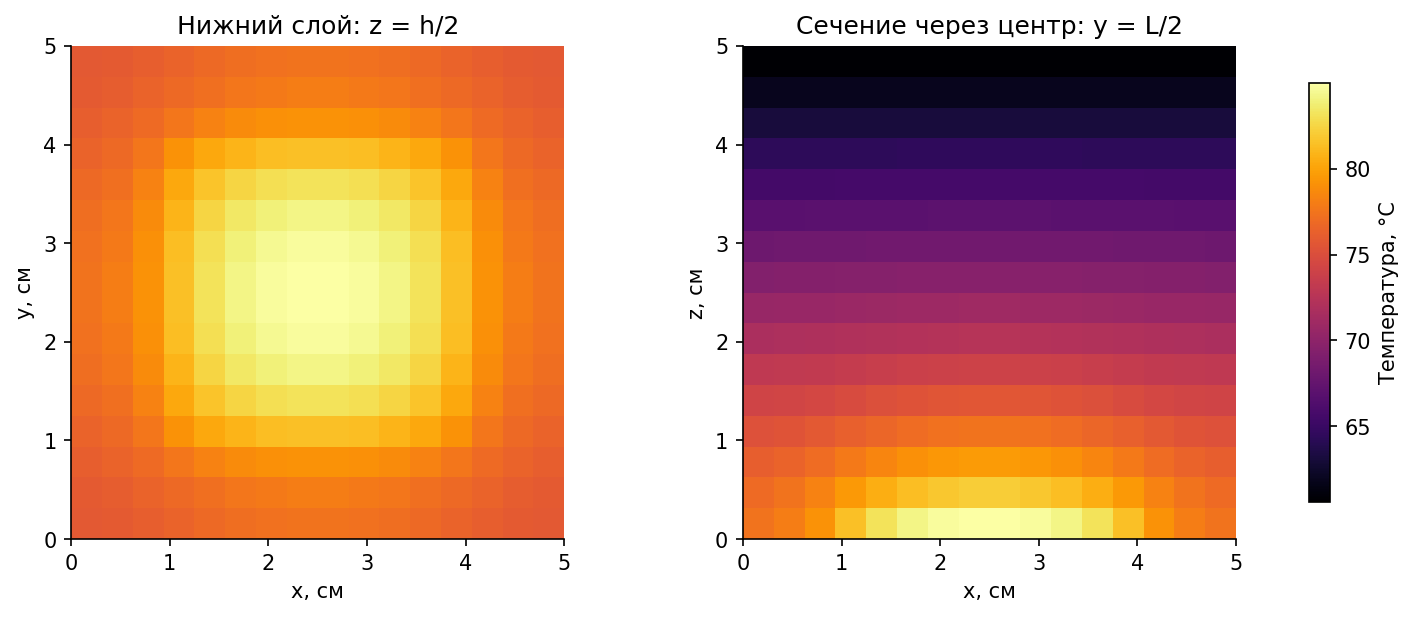

*Температура в центрах ячеек при охлаждении сверху. Центральное сечение получено усреднением двух ближайших слоёв по y.*

**Объяснение результата.** Наиболее горячая область находится рядом с центральной площадкой нагрева. По пути к верхней охлаждаемой грани температура уменьшается: именно этот перепад обеспечивает перенос тепла внутри металла. Углы и участки вдали от площадки получают тепло через материал и нагреваются слабее.

Температура охлаждаемой поверхности выше температуры воды. Для отвода ненулевой мощности по закону Ньютона необходим ненулевой перепад температуры. Почти точное равенство отведённых 200 Вт подведённой мощности подтверждает выполнение дискретного теплового баланса.

На рисунках показаны температуры **центров ячеек**. Значение максимума контакта из таблицы дополнительно учитывает перепад на половине нижней ячейки, поэтому оно может быть выше максимума цветовой шкалы.

## 9. Сравнение итерационных методов

Сравнение выполнено на одной и той же сетке $16^3$ для базового случая. Во всех методах одинаковы начальное приближение $u=0$, СЛАУ и критерий остановки $r<10^{-8}$. Для SOR взято $\omega=1{,}97$.

Методы отличаются способом получения решения одной системы, поэтому должны давать практически одинаковые температуры. Сравнивать их удобно по числу итераций и времени работы.

| Метод | Итерации | Время, с | Максимум контакта, °C | Конечная невязка |
| --- | --- | --- | --- | --- |
| Якоби | 50108 | 4,275 | 86,71140 | 1.00e-08 |
| Зейдель | 26226 | 5,435 | 86,71141 | 1.00e-08 |
| SOR | 644 | 0,169 | 86,71142 | 9.96e-09 |

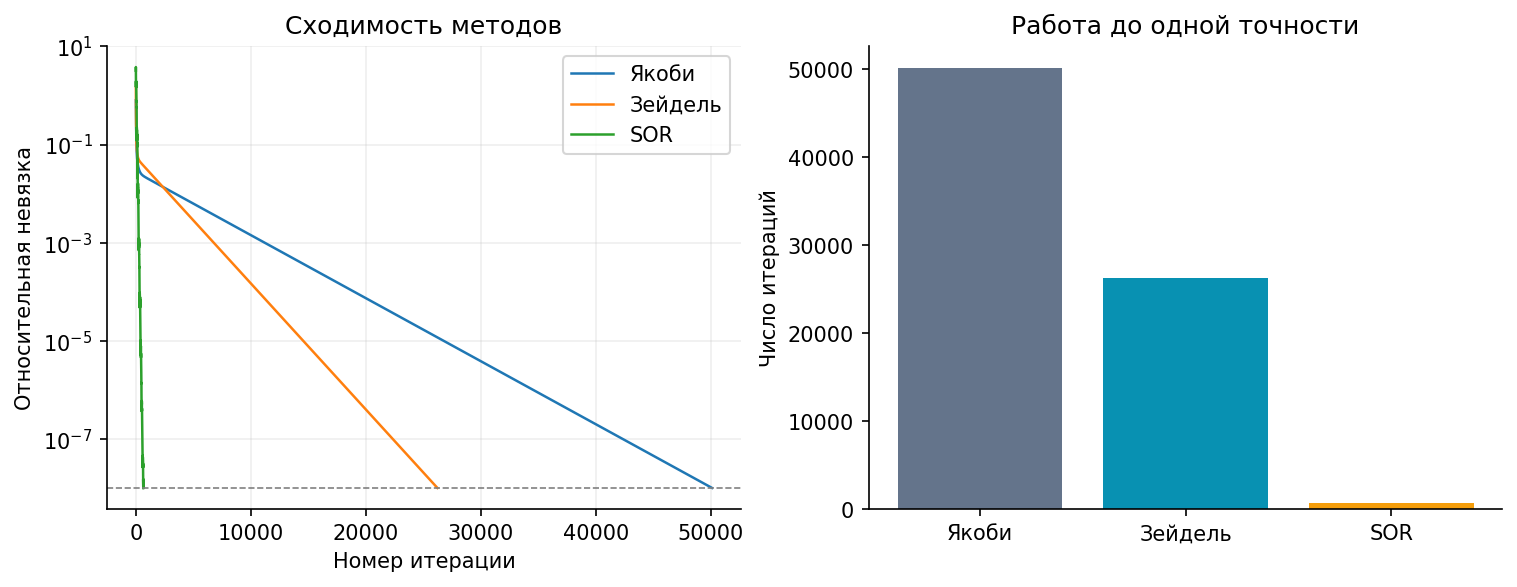

*Сравнение методов для базового случая. Невязка SOR может колебаться, но к окончанию расчёта достигает заданного порога.*

**Выводы по сравнению методов.**

- Все три метода дают одинаковую температуру при округлении до сотых градуса. Разница между ними состоит прежде всего в скорости сходимости.
- Метод Якоби требует больше всего итераций. Зейдель использует уже обновлённые значения и в данном примере требует меньше итераций. Однако по измеренному времени Зейдель оказался медленнее Якоби: в данной реализации на каждом шаге дважды пересчитываются суммы соседей и выполняются обновления по маскам.
- SOR с выбранным параметром требует примерно в 77,8 раза меньше итераций, чем Якоби. Поэтому в приложении используется SOR.
- Одна итерация Якоби и одна итерация SOR требуют разного объёма вычислений. Поэтому отношение числа итераций не обязано совпадать с отношением времени.

Время в таблице измерено один раз для самого итерационного решателя, без построения графиков и работы интерфейса. На другом компьютере оно изменится. Параметр $\omega=1{,}97$ здесь не объявляется оптимальным для всех сеток и условий.

## 10. Как выбор охлаждаемых граней влияет на результат

Сохраним базовые параметры и сетку $N=16$, изменяя только набор охлаждаемых граней. На каждой выбранной грани действует один и тот же коэффициент теплоотдачи $\alpha=2000$ Вт/(м²·К).

| Охлаждение | Грани | Максимум контакта, °C | Средняя температура контакта, °C |
| --- | --- | --- | --- |
| Верхняя грань | z+ | 86,711 | 84,330 |
| Одна боковая | x+ | 81,935 | 78,629 |
| Две противоположные | x-, x+ | 56,222 | 53,517 |
| Две соседние | x+, y+ | 58,145 | 55,087 |
| Все пять граней | x-, x+, y-, y+, z+ | 43,875 | 41,180 |

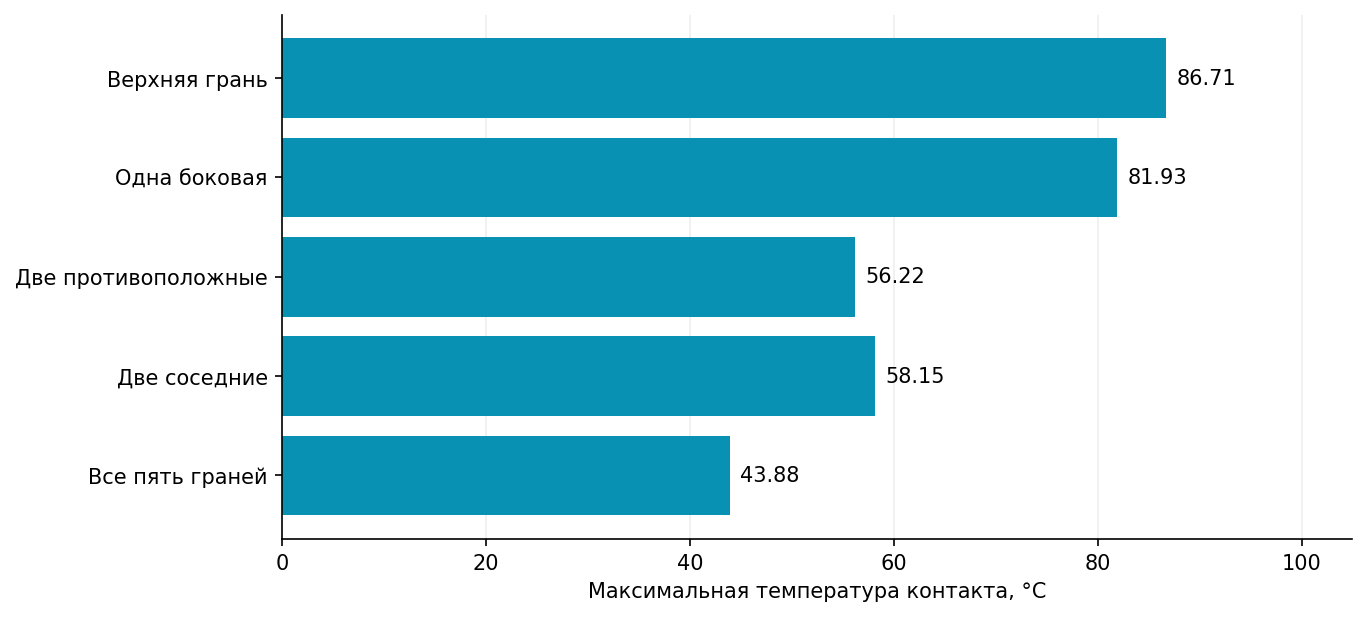

*Сравнение способов охлаждения при одинаковых мощности, сетке и коэффициенте теплоотдачи.*

**Простые выводы.**

- В рассмотренных вариантах охлаждение всех пяти доступных граней даёт наименьшую максимальную температуру контакта.
- Одна боковая грань в этом примере охлаждает эффективнее, чем одна верхняя. Площади одинаковы, но расположение относительно нагреваемой нижней площадки различается.
- Две противоположные боковые грани дают меньшую температуру, чем две соседние. Следовательно, важна не только площадь охлаждения, но и её расположение.
- Эти результаты относятся к выбранной геометрии и параметрам. При сравнении в модели на каждой грани сохраняется тот же коэффициент теплоотдачи; расход воды и устройство каналов не рассчитываются.

## 11. Проверка при сгущении сетки

Малая невязка означает, что итерационный метод хорошо решил заданную СЛАУ. Чтобы проверить влияние размера ячейки, нужно повторить расчёт на более мелкой сетке.

Для охлаждения сверху выполнены расчёты при $N=10,20,40$ с теми же физическими параметрами и точностью итераций. Эти сетки выбраны так, чтобы края площадки совпадали с границами нижних ячеек: при $a/L=0{,}6$ края расположены в координатах $0{,}2L$ и $0{,}8L$. Это упрощает сравнение.

| N | Число ячеек | Шаг h, мм | Максимум контакта, °C | Средняя температура контакта, °C |
| --- | --- | --- | --- | --- |
| 10 | 1000 | 5,000 | 86,82768 | 84,99245 |
| 20 | 8000 | 2,500 | 86,74271 | 84,49100 |
| 40 | 64000 | 1,250 | 86,72442 | 84,32859 |

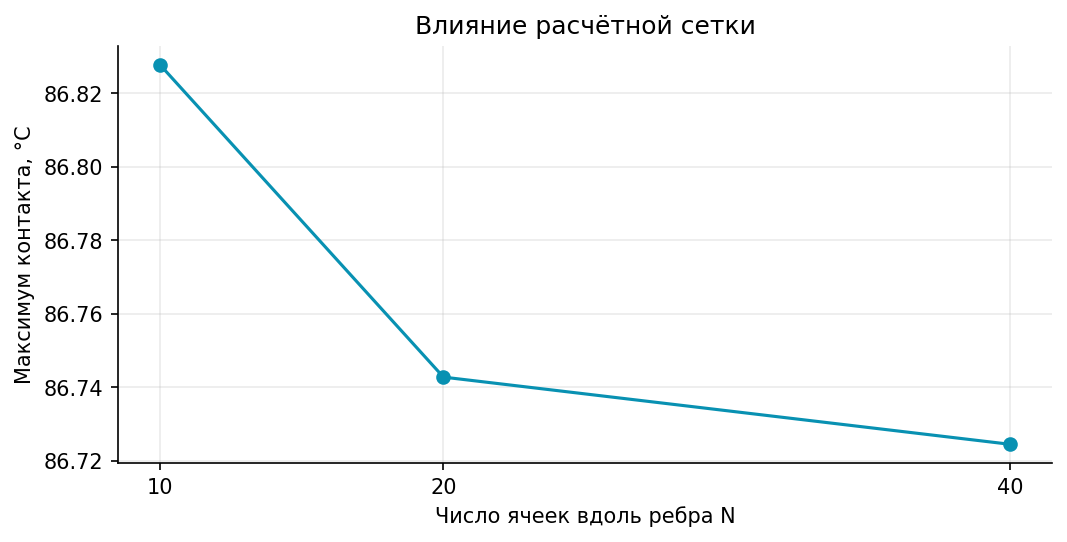

*Изменение максимальной температуры контакта при сгущении сетки; вертикальная шкала увеличена для различимости небольших изменений.*

**Вывод.** Между сетками $20^3$ и $40^3$ максимальная температура контакта меняется на 0,0183 °C. Это небольшое изменение по сравнению с различиями между способами охлаждения. Поэтому для наглядного сравнения режимов умеренная сетка уже полезна, а для уточнения температуры её можно сгущать.

Разность между двумя сетками служит практическим ориентиром, но не является строгой оценкой ошибки относительно точного решения. По этой проверке не делается утверждение о порядке точности всей задачи. При произвольных $N$ результат может изменяться немонотонно из-за частичного перекрытия ячеек площадкой и восстановления температуры поверхности.

## 12. Влияние параметров

### 12.1. Коэффициент теплоотдачи

Изменим $\alpha$, оставив остальные параметры базовыми. Охлаждается только верхняя грань, $N=16$.

| α, Вт/(м²·К) | Максимум контакта, °C |
| --- | --- |
| 500 | 206,711 |
| 1000 | 126,711 |
| 2000 | 86,711 |
| 5000 | 62,711 |
| 10000 | 54,711 |

При увеличении коэффициента теплоотдачи температура контакта уменьшается: тепло легче передаётся от поверхности радиатора воде. Однако тепло по-прежнему должно пройти через сам металл, поэтому увеличение $\alpha$ не устраняет температурные перепады внутри радиатора.

### 12.2. Мощность процессора

Теперь изменим только мощность, сохранив $\alpha=2000$ Вт/(м²·К), охлаждение сверху и $N=16$.

| P, Вт | Максимум контакта, °C | Превышение максимума над водой, °C |
| --- | --- | --- |
| 100 | 53,356 | 33,356 |
| 200 | 86,711 | 66,711 |
| 400 | 153,423 | 133,423 |

При удвоении мощности в этой модели удваивается **превышение температуры над температурой воды**, а не сама температура в градусах Цельсия. Это следует из линейности СЛАУ: правая часть пропорциональна мощности, а коэффициенты матрицы при неизменных остальных параметрах остаются теми же.

Например, при переходе от 100 к 200 Вт превышение максимума над водой увеличивается вдвое. Такой результат согласуется с физическим смыслом модели и служит дополнительной проверкой реализации.

## 13. Что учитывает модель и как читать графики

Модель описывает установившуюся теплопроводность в однородном кубическом радиаторе. Она позволяет сравнивать охлаждаемые грани и оценивать влияние мощности, теплоотдачи и сетки.

При интерпретации результатов нужно помнить следующее:

- Температура воды задана постоянной. Её нагрев при прохождении вдоль радиатора отдельно не рассчитывается.
- Коэффициенты $\lambda$ и $\alpha$ не зависят от температуры. На всех выбранных гранях используется одно и то же $\alpha$.
- Процессор задаёт входящую мощность через площадку. Температуру его кристалла нельзя напрямую отождествлять с вычисленной температурой контакта радиатора.
- У частично перекрытых площадкой ячеек температура контакта восстанавливается по потоку, усреднённому по всей нижней грани ячейки. Это приближение уже отмечено в разделе 6.
- Плавность изображения не означает измельчения расчётной сетки. В `graphics.py` значения интерполируются только для отображения; новые уравнения при этом не решаются.

**Изотермические поверхности** соединяют точки с одинаковой температурой. **Температурные сечения** показывают изменение температуры внутри выбранной плоскости. Цветовая шкала приложения относится к полю температур центров ячеек. В крайних половинах ячеек на сечениях продолжается ближайшее значение центра; это не отдельный расчёт температуры внешней поверхности.

Эти допущения позволяют сохранить задачу достаточно простой и при этом описать основные пути отвода тепла.

## 14. Итоговые выводы

1. Построена стационарная модель радиатора без внутренних источников тепла. Мощность процессора поступает через квадратную площадку на нижней грани, а отводится через выбранные охлаждаемые грани.
2. Баланс тепла в ячейках приводит к СЛАУ. В проверенных расчётах суммарная отведённая мощность согласуется с подведённой, а относительная невязка меньше $10^{-8}$.
3. Якоби, Зейдель и SOR дают практически одинаковые температуры. Для базового примера SOR с $\omega=1{,}97$ требует меньше итераций, поэтому выбран для приложения.
4. При охлаждении только сверху максимальная температура контакта составляет около 86,71 °C. При охлаждении всех пяти доступных граней она снижается примерно до 43,88 °C.
5. На результат влияют и площадь, и расположение охлаждаемых граней. В рассмотренном примере две противоположные боковые грани охлаждают лучше двух соседних.
6. Сгущение сетки с $20^3$ до $40^3$ меняет максимум контакта на 0,0183 °C. Для данного режима результат слабо меняется при таком уточнении.
7. Рост мощности увеличивает превышение температуры над водой пропорционально мощности. Увеличение коэффициента теплоотдачи уменьшает температуру радиатора.

Полученная программа подходит для сравнения режимов охлаждения в рамках принятых допущений. Основной результат — распределение температуры в радиаторе и оценка температуры его контактной поверхности.